### Important Note
The code is organized in the following way:
- First imports and useful functions are defined;
- Assessing the effect of different X distributions/processes on bimodality (X=0; X~N(0,sd); X~Student-t;X~AR(1));
- Assessing the effect of different betas on bimodality;
- Assessing the effect of standard deviation on bimodality (for X following a normal distribution);
- Assessing the effect of AR(1) coefficient on bimodality (for X following a AR(1) process).

---
### MARX(1,1,1) Simulation with Cauchy Innovations

$$
(1-\phi L)(1-\psi L^{-1})y_t = z_t
$$

with

$$
z_t = \beta X_t + \varepsilon_t
$$


Using the noncausal component $u_t = (1-\phi L)y_t$:

$$
(1-\psi L^{-1})u_t = z_t
\quad\Rightarrow\quad
u_t = z_t + \psi u_{t+1}
$$

and then recover $y_t$ from

$$
(1-\phi L)y_t = u_t
\quad\Rightarrow\quad
y_t = u_t + \phi y_{t-1}.
$$


### Predictive Density

$$
l(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [2]:
# DEFINING FUNCTIONS

# =========================================================
# Generate X under different specifications
# =========================================================
def generate_X(N, kind):
    if kind == "zero":
        return np.zeros(N)

    elif kind == "normal1":
        return np.random.normal(0, 1, N)

    elif kind == "normal2":
        return np.random.normal(0, 10, N)
    
    elif kind == "student_t_nu3":
        return np.random.standard_t(3,N)

    elif kind == "ar1_1":
        X = np.zeros(N)
        eta = np.random.normal(0, 1, N)
        rho = 0.3
        for t in range(1, N):
            X[t] = rho * X[t-1] + eta[t]
        return X

    elif kind == "ar1_2":
        X = np.zeros(N)
        eta = np.random.normal(0, 1, N)
        rho = 0.8
        for t in range(1, N):
            X[t] = rho * X[t-1] + eta[t]
        return X
    
    elif kind == "ar1_studentt_1":
        X = np.zeros(N)
        eta = np.random.standard_t(3,N)
        rho = 0.3
        for t in range(1, N):
            X[t] = rho * X[t-1] + eta[t]
        return X
    
    elif kind == "ar1_studentt_2":
        X = np.zeros(N)
        eta = np.random.standard_t(3,N)
        rho = 0.8
        for t in range(1, N):
            X[t] = rho * X[t-1] + eta[t]
        return X

    else:
        raise ValueError("Unknown X type")


# =========================================================
# Simulate MARX(1,1,1)
# =========================================================
def simulate_marx(T, phi, psi, beta, X, eps, burn=50, extra=50):
    N = T + burn + extra

    if len(X) != N:
        raise ValueError(f"X must have length {N}, got {len(X)}")
    if len(eps) != N:
        raise ValueError(f"eps must have length {N}, got {len(eps)}")

    z = beta * X + eps

    u = np.zeros(N)
    for t in range(N - 2, -1, -1):
        u[t] = z[t] + psi * u[t + 1]

    y = np.zeros(N)
    y[0] = u[0]
    for t in range(1, N):
        y[t] = u[t] + phi * y[t - 1]

    return y[burn:burn + T], X[burn:burn + T]


# =========================================================
# Predictive density
# =========================================================
def marx11_cauchy_pred_density(y_next, y, X, t, phi, psi, beta, sigma):
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    if not (1 <= t < len(y)):
        raise ValueError(f"t must satisfy 1 <= t < len(y), got t={t}")

    y_t = y[t]
    y_tm1 = y[t - 1]
    X_t = X[t]

    u_t = y_t - phi * y_tm1
    z_next = y_next - phi * y_t

    term1 = 1.0 / (np.pi * sigma)
    term2 = sigma**2 / ((u_t - psi * z_next - beta * X_t)**2 + sigma**2)
    term3 = (sigma**2 + (1 - abs(psi))**2 * u_t**2) / (
        sigma**2 + (1 - abs(psi))**2 * z_next**2
    )

    return term1 * term2 * term3


# =========================================================
# Bimodality measure
# =========================================================
def bimodality_measure(y, X, t, phi, psi, beta, sigma, grid):
    dens = marx11_cauchy_pred_density(grid, y, X, t, phi, psi, beta, sigma)

    area = np.trapezoid(dens, grid)
    if area <= 0 or not np.isfinite(area):
        return 0.0
    dens = dens / area

    peaks, _ = find_peaks(dens, prominence=0.02 * dens.max())

    if len(peaks) < 2:
        return 0.0

    top2 = peaks[np.argsort(dens[peaks])[-2:]]
    top2 = np.sort(top2)

    p1, p2 = top2
    h1, h2 = dens[p1], dens[p2]

    valley_idx = p1 + np.argmin(dens[p1:p2+1])
    valley_h = dens[valley_idx]

    return (min(h1, h2) / max(h1, h2)) * (1 - valley_h / min(h1, h2))


def bimodality_series(y, X, phi, psi, beta, sigma, grid):
    vals = []
    for t in range(1, len(y)):
        vals.append(bimodality_measure(y, X, t, phi, psi, beta, sigma, grid))
    return np.array(vals)

### Assessing the effect of different X distributions/processes on bimodality

Note: The same Cauchy innovations are used on all DGPs and no MLE is performed, (the real values are used to obtain predictive density and bimodality) for comparability.

In [3]:
# =========================================================
# Parameters + Use functions
# =========================================================
T = 400
H = 50
burn = 25
extra = 25


phi = 0.3
psi = 0.5
beta = 0.3
sigma = 1.0

grid = np.linspace(-180, 180, 4000)

cases = {
    "X = 0": "zero",
    "Normal sd=1": "normal1",
    "Normal sd=10": "normal2",
    "Student't nu=3": "student_t_nu3",
    "AR(1) rho=0.3": "ar1_1",
    "AR(1) rho=0.8": "ar1_2",
    "AR(1) rho=0.3 Student't nu=3": "ar1_studentt_1",
    "AR(1) rho=0.8 Student't nu=3": "ar1_studentt_2"
}


results = {}

N = T + burn + extra

np.random.seed(42)
eps = sigma * np.random.standard_cauchy(size=N)

np.random.seed(100)

for name, kind in cases.items():
    X_full = generate_X(N, kind)

    y, X = simulate_marx(
        T=T,
        phi=phi,
        psi=psi,
        beta=beta,
        X=X_full,
        eps=eps,
        burn=burn,
        extra=extra
    )

    b = bimodality_series(y, X, phi, psi, beta, sigma, grid)

    results[name] = {
        "X": X,
        "y": y,
        "b": b
    }


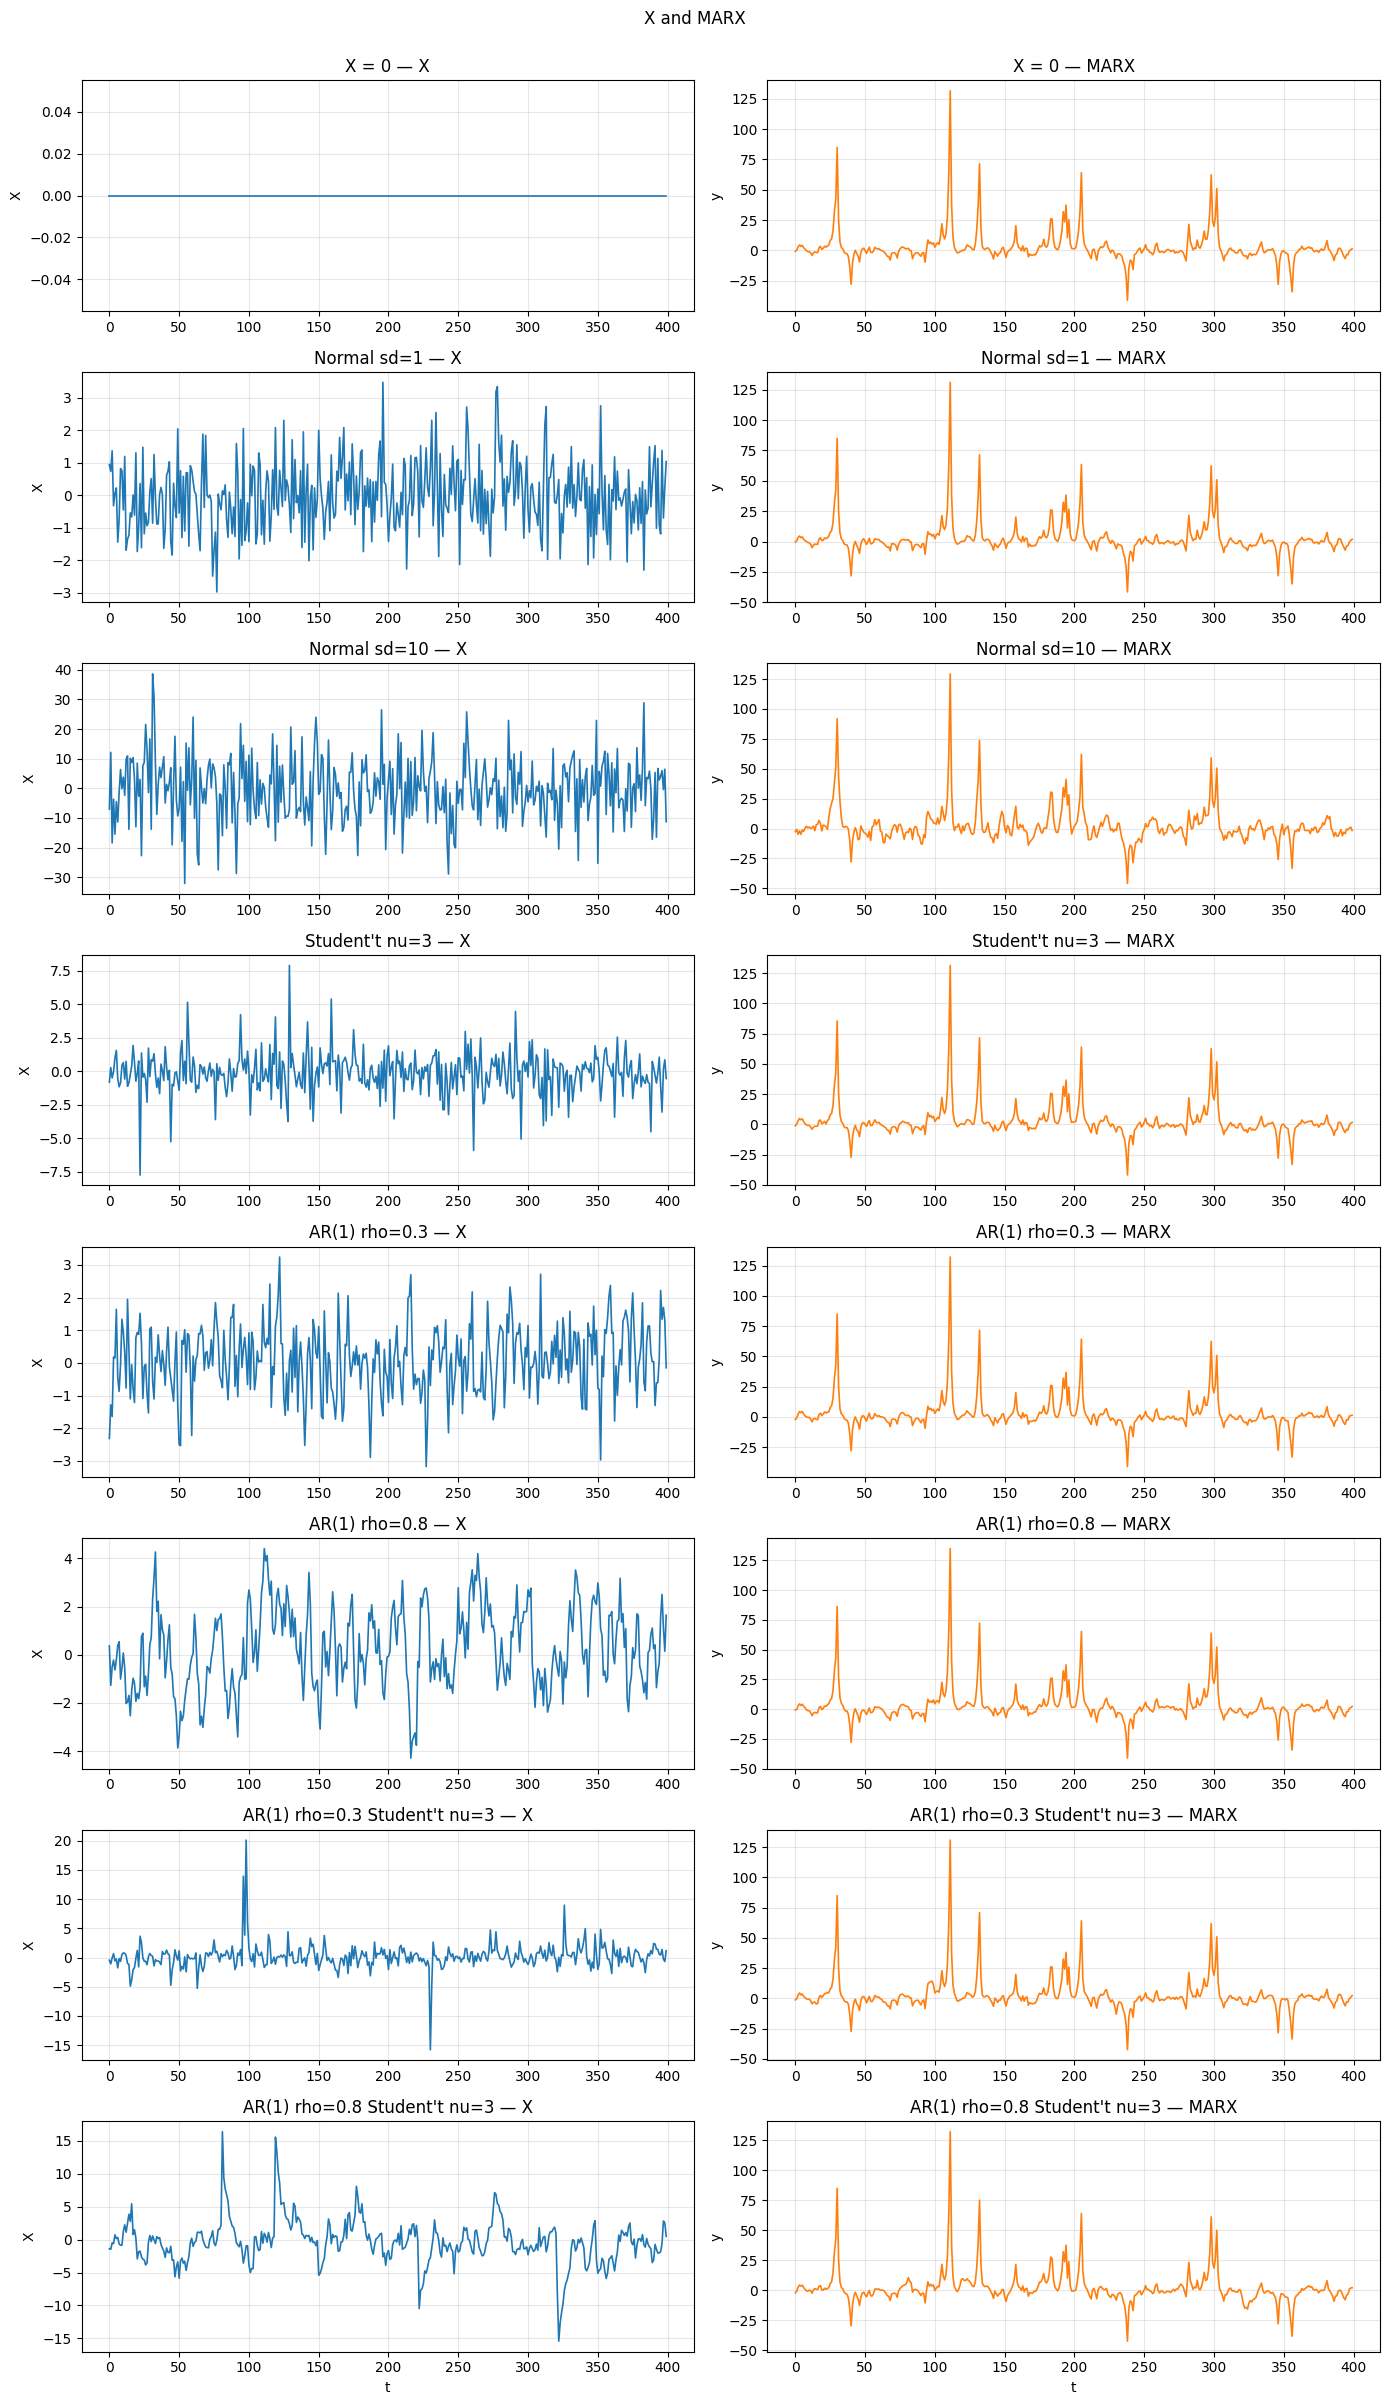

In [4]:
# =========================================================
# Plot X (left) and MARX (right)
# =========================================================
labels = list(results.keys())
n = len(labels)

fig, axes = plt.subplots(n, 2, figsize=(14, 3*n), sharex=False)

if n == 1:
    axes = np.array([axes])

for i, (name, res) in enumerate(results.items()):
    ax_X = axes[i, 0]
    ax_y = axes[i, 1]

    # Left: X
    ax_X.plot(res["X"], lw=1.2, color="tab:blue")
    ax_X.set_title(f"{name} — X")
    ax_X.set_ylabel("X")
    ax_X.grid(True, alpha=0.3)

    # Right: MARX (y)
    ax_y.plot(res["y"], lw=1.2, color="tab:orange")
    ax_y.set_title(f"{name} — MARX")
    ax_y.set_ylabel("y")
    ax_y.grid(True, alpha=0.3)

# x-label
axes[-1, 0].set_xlabel("t")
axes[-1, 1].set_xlabel("t")

fig.suptitle("X and MARX", y=1.0)
plt.tight_layout()
plt.show()

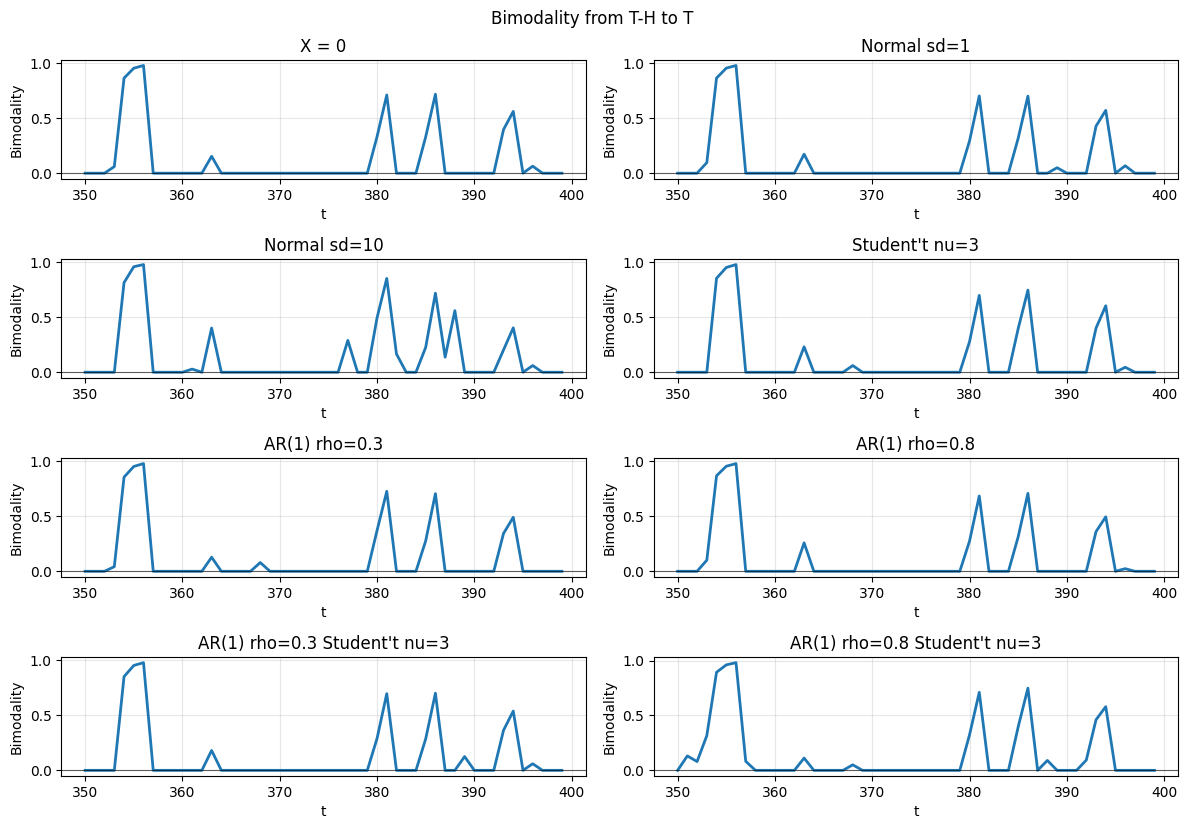

In [5]:
# =========================================================
# Plot bimodality from T-H onwards
# =========================================================
fig, axes = plt.subplots(5, 2, figsize=(12, 10), sharex=False, sharey=False)
axes = axes.ravel()

times_lastH = np.arange(T-H, T)

for ax, (name, res) in zip(axes, results.items()):
    b_lastH = res["b"][-H:]   # keep only last H bimodality values

    ax.plot(times_lastH, b_lastH, lw=2)
    ax.axhline(0, color="black", lw=0.8, alpha=0.6)
    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("Bimodality")
    ax.grid(True, alpha=0.3)

# remove the unused subplot
for j in range(len(results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(f"Bimodality from T-H to T ")
plt.tight_layout()
plt.show()

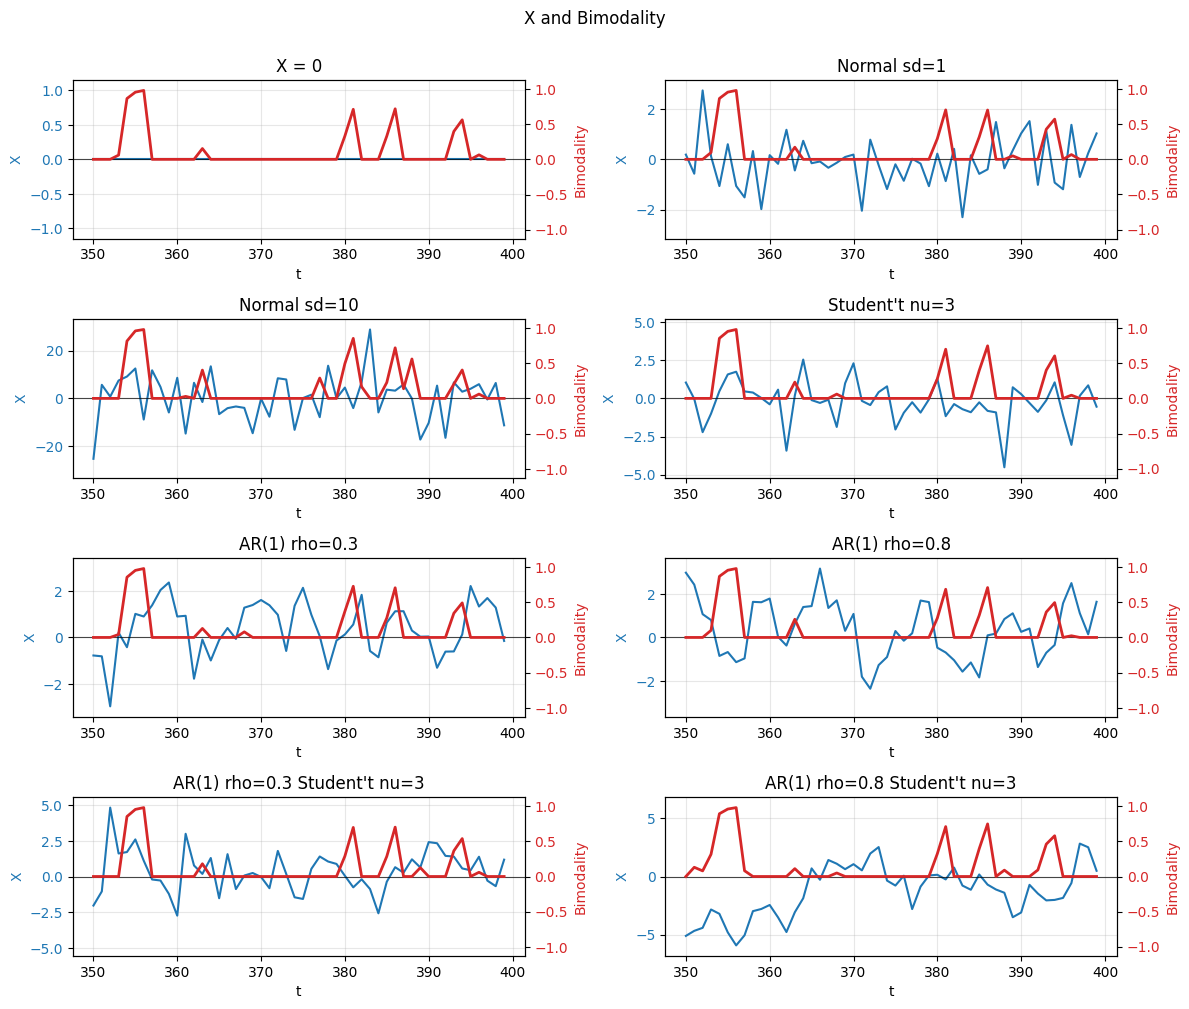

In [6]:
# =========================================================
# Plot X and bimodality from T-H onwards
# =========================================================
fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=False)
axes = axes.ravel()

times_lastH = np.arange(T - H, T)

for ax, (name, res) in zip(axes, results.items()):
    X_lastH = res["X"][-H:]
    b_lastH = res["b"][-H:]

    # left axis: X
    ax.plot(times_lastH, X_lastH, lw=1.5, color="tab:blue", label="X")
    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("X", color="tab:blue")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.grid(True, alpha=0.3)

    # right axis: bimodality
    ax2 = ax.twinx()
    ax2.plot(times_lastH, b_lastH, lw=2.0, color="tab:red", label="Bimodality")
    ax2.set_ylabel("Bimodality", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    # force both axes to be symmetric around zero
    x_lim = np.max(np.abs(X_lastH))
    b_lim = np.max(np.abs(b_lastH))

    if x_lim == 0:
        x_lim = 1.0
    if b_lim == 0:
        b_lim = 1.0

    # add padding
    pad = 1.15

    ax.set_ylim(-pad * x_lim, pad * x_lim)
    ax2.set_ylim(-pad * b_lim, pad * b_lim)

    # zero line
    ax.axhline(0, color="black", lw=0.8, alpha=0.7)

# remove the unused subplot
for j in range(len(results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(f"X and Bimodality", y=1)
plt.tight_layout()
plt.show()

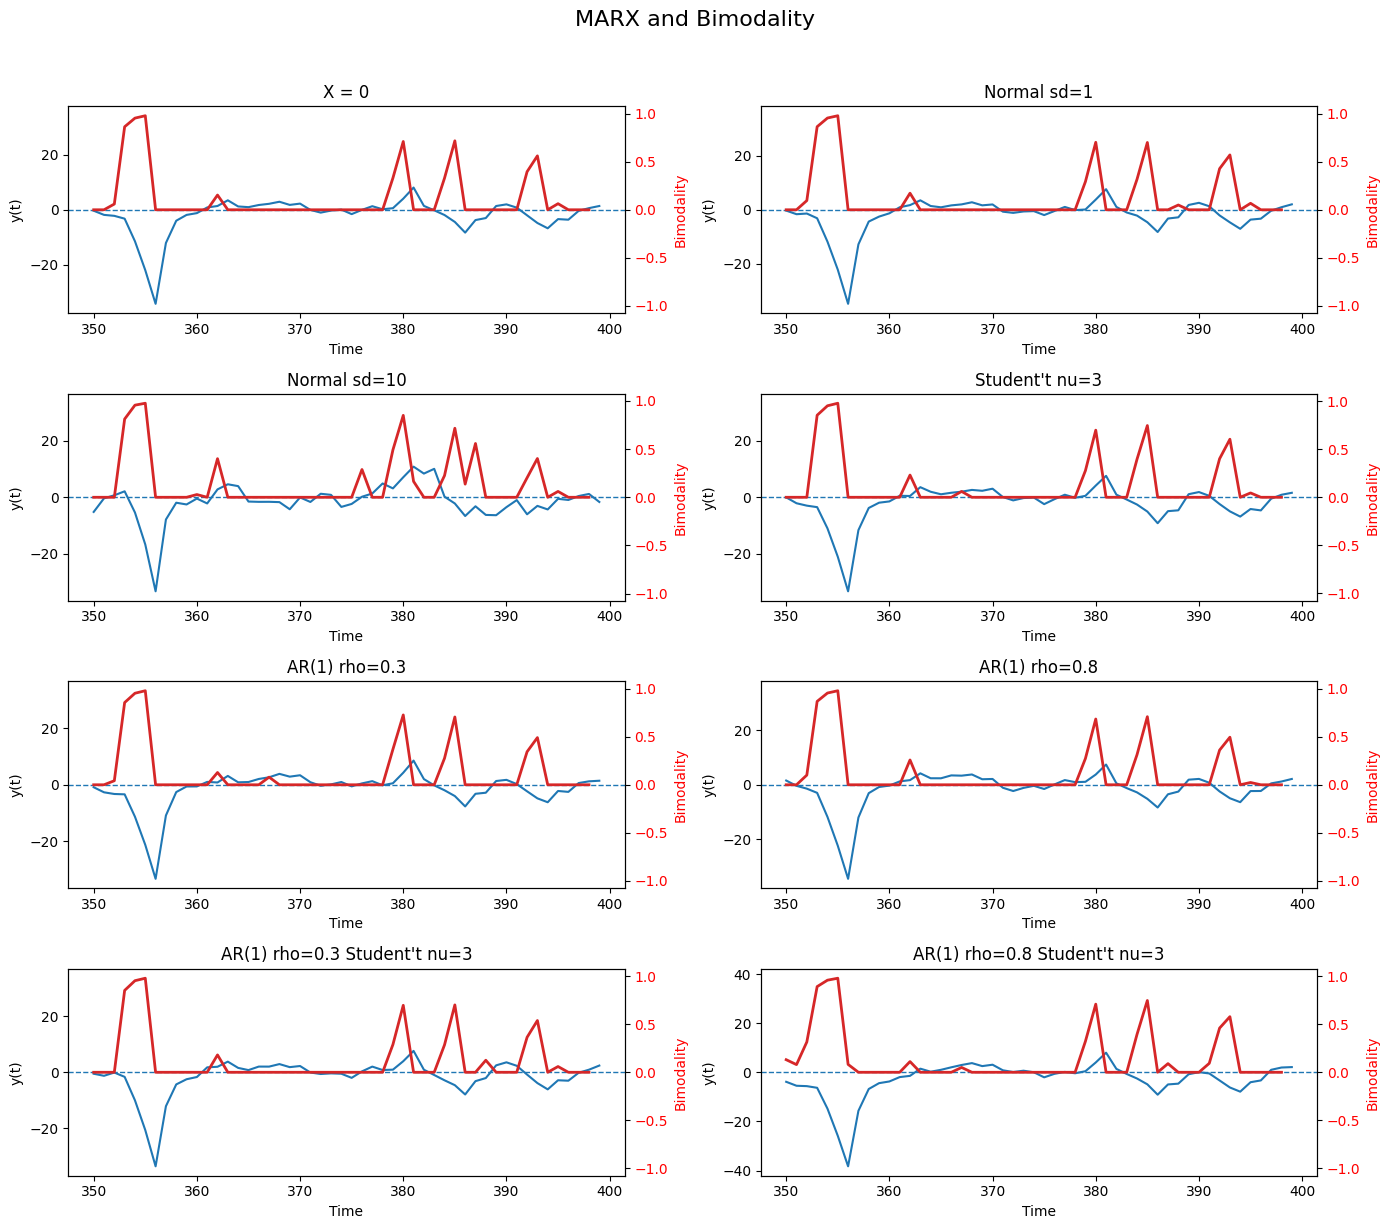

In [7]:
# =========================================================
# Plot MARX and Bimodality from T-H onwards
# =========================================================

cases_list = list(results.keys())
n_cases = len(cases_list)

ncols = 2
nrows = int(np.ceil(n_cases / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14,3*nrows))
axes = np.atleast_1d(axes).flatten()

for i, name in enumerate(cases_list):
    ax1 = axes[i]
    ax2 = ax1.twinx()

    y = results[name]["y"]
    b = results[name]["b"]

    # Focus on last H observations
    start = len(y) - H
    end = len(y)

    y_plot = y[start:end]
    b_plot = b[start:end-1 ]   # b is one element shorter than y

    t_y = np.arange(start, end)
    t_b = np.arange(start, end-1)

    # Plot MARX
    ax1.plot(t_y, y_plot,lw=1.5, color="tab:blue", label="MARX")
    ax1.axhline(0, linestyle="--", linewidth=1)

    # Plot bimodality in red, solid
    ax2.plot(t_b, b_plot, lw=2.0, color="tab:red", label="Bimodality")

    # Padding so lines don't touch bounds
    y_lim = max(abs(y_plot.min()), abs(y_plot.max()))
    b_lim = max(abs(b_plot.min()), abs(b_plot.max()))

    y_pad = 1.1 if y_lim > 0 else 1.0
    b_pad = 1.1 if b_lim > 0 else 1.0

    ax1.set_ylim(-y_pad * y_lim, y_pad * y_lim)
    ax2.set_ylim(-b_pad * b_lim, b_pad * b_lim)

    # Labels and title
    ax1.set_title(name)
    ax1.set_xlabel("Time")
    ax1.set_ylabel("y(t)")
    ax2.set_ylabel("Bimodality", color="red")
    ax2.tick_params(axis="y", labelcolor="red")

# Remove empty axes if number of cases is odd
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("MARX and Bimodality", fontsize=16, y=1.02)
fig.tight_layout()
plt.show()

----
## Effect of certain parameters on bimodality

### Assessing the effect of different betas on bimodality

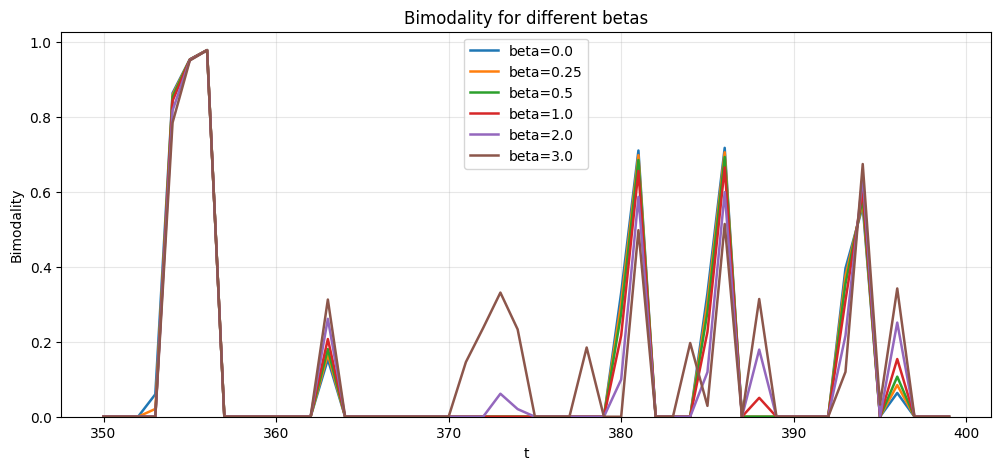

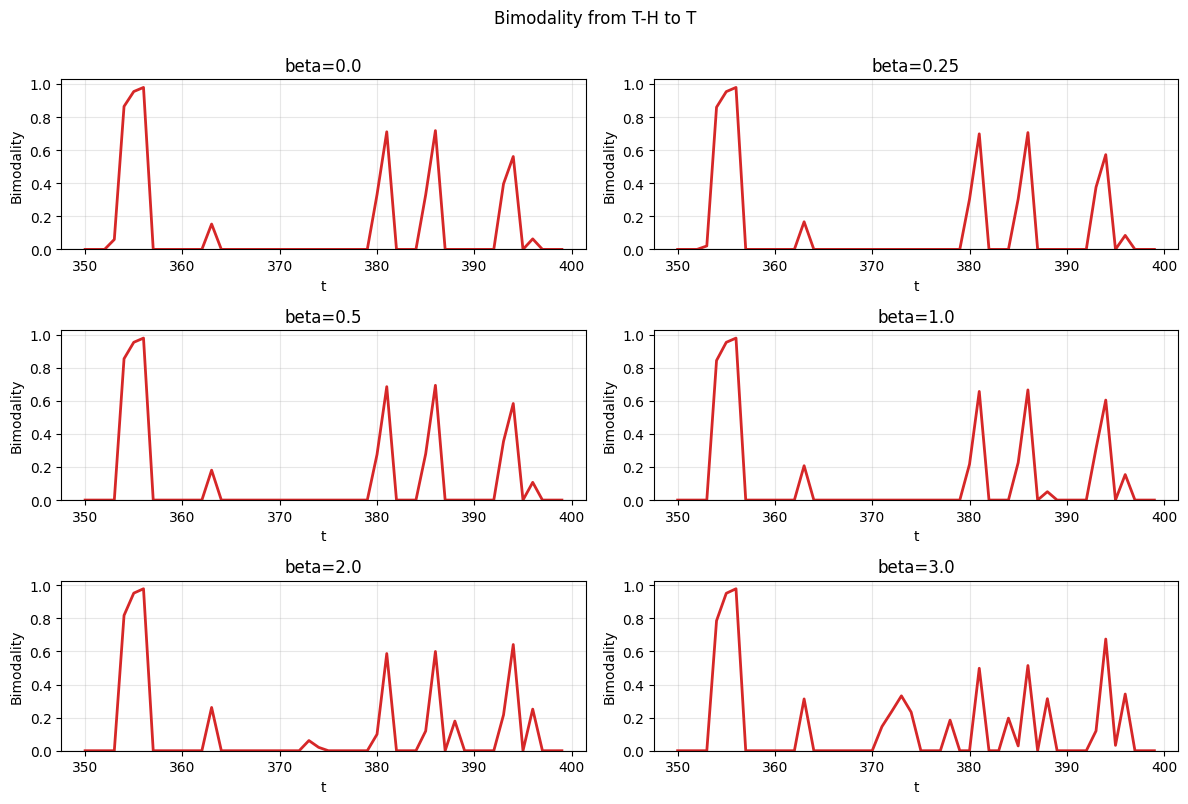

In [8]:
# =========================================================
# Effect of different betas
# =========================================================
betas = [0.0, 0.25, 0.5, 1.0, 2.0, 3.0]

exp1_results = {}
N = T + burn + extra

# same shocks for all betas
np.random.seed(42)
common_eps = sigma * np.random.standard_cauchy(size=N)

# same X for all betas
np.random.seed(101)
X_full_common = generate_X(N, "normal1")

for beta_val in betas:
    y, X = simulate_marx(
        T=T,
        phi=phi,
        psi=psi,
        beta=beta_val,
        X=X_full_common,
        eps=common_eps,
        burn=burn,
        extra=extra
    )

    b = bimodality_series(y, X, phi, psi, beta_val, sigma, grid)

    exp1_results[f"beta={beta_val}"] = {
        "X": X,
        "y": y,
        "b": b
    }

"""
# Plot X (same for all betas)
common_X = list(exp1_results.values())[0]["X"]

plt.figure(figsize=(12, 4))
plt.plot(times_lastH, common_X[-H:], lw=1.8)
plt.title("X")
plt.xlabel("t")
plt.ylabel("X")
plt.grid(True, alpha=0.3)
plt.show()"""

# Plot bimodality for all betas
plt.figure(figsize=(12, 5))

for label, res in exp1_results.items():
    plt.plot(times_lastH, res["b"][-H:], lw=1.8, label=label)

plt.title("Bimodality for different betas")
plt.xlabel("t")
plt.ylabel("Bimodality")
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Plot bimodality from T-H onwards
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=False, sharey=False)
axes = axes.ravel()

times_lastH = np.arange(T - H, T)

for ax, (name, res) in zip(axes, exp1_results.items()):
    b_lastH = res["b"][-H:]

    ax.plot(times_lastH, b_lastH, lw=2, color="tab:red")
    ax.axhline(0, color="black", lw=0.8, alpha=0.6)

    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("Bimodality")
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

# remove unused subplot
for j in range(len(exp1_results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Bimodality from T-H to T", y=1)
plt.tight_layout()
plt.show()

### Assessing the effect of standard deviation on bimodality (for X following a normal distribution)

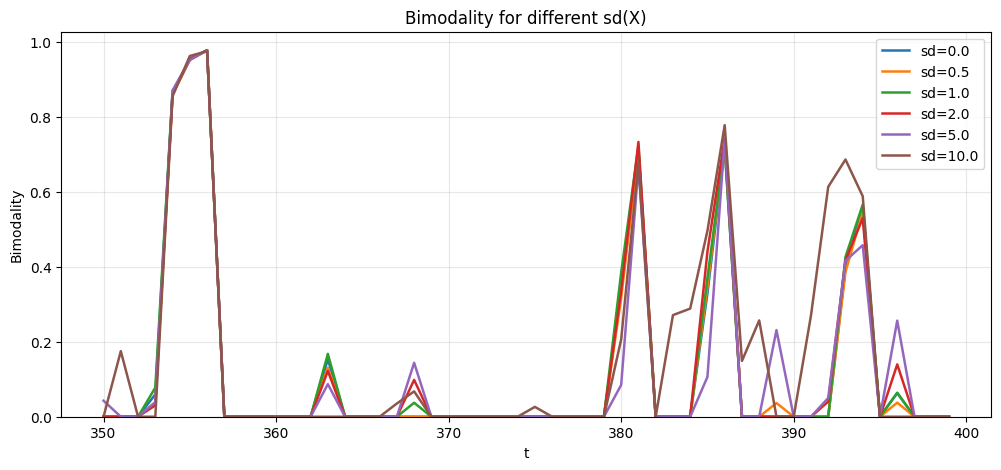

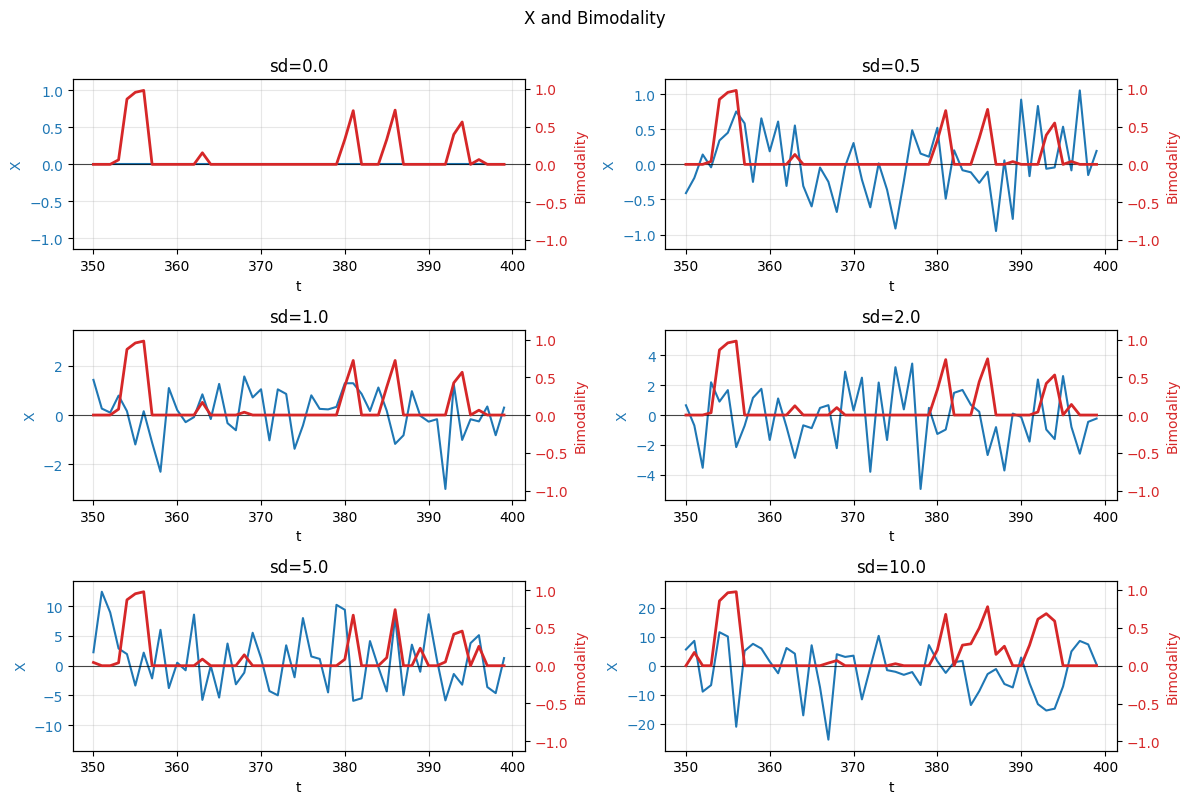

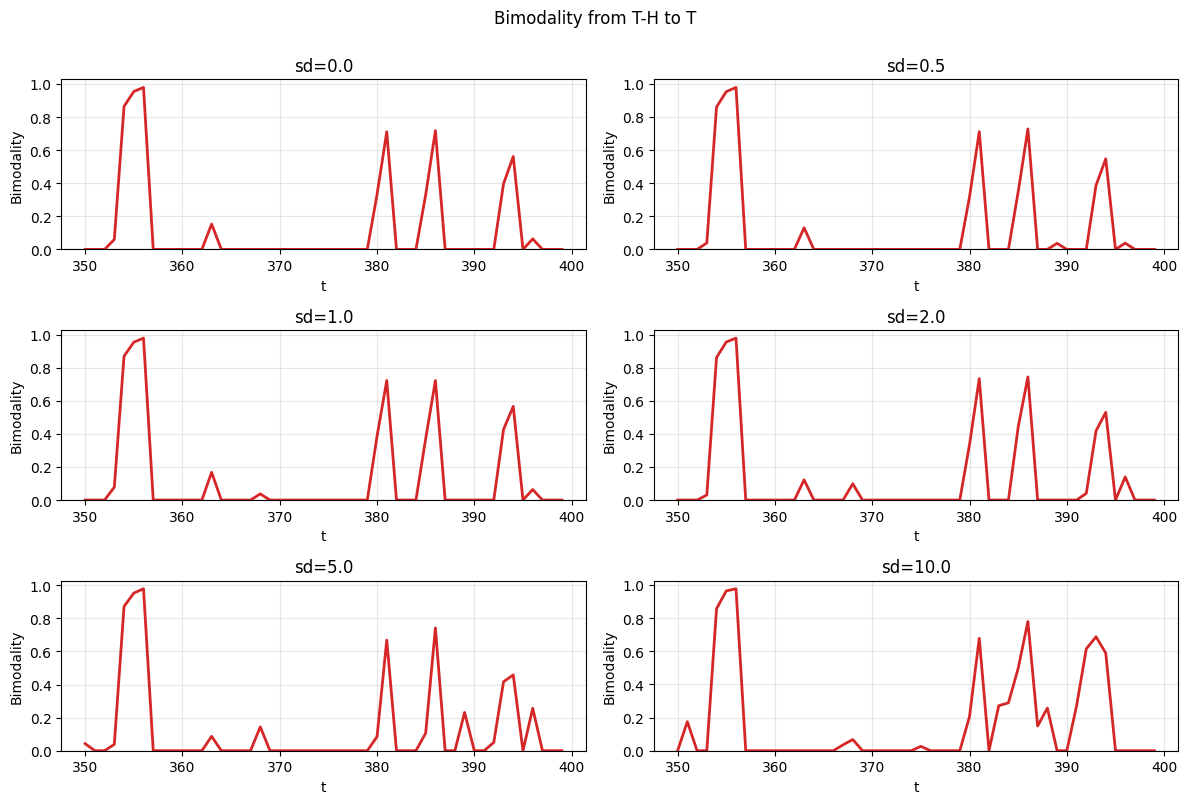

In [9]:
# =========================================================
# Effect of standard deviation for X following a normal distribution
# =========================================================

def generate_normal_X(N, sd):
    return np.random.normal(0, sd, N)

sds = [0.0, 0.5, 1.0, 2.0, 5.0, 10.0]

exp2_results = {}
N = T + burn + extra

np.random.seed(42)
common_eps = sigma * np.random.standard_cauchy(size=N)

np.random.seed(200)

for sd_val in sds:
    X_full = generate_normal_X(N, sd=sd_val)

    y, X = simulate_marx(
        T=T,
        phi=phi,
        psi=psi,
        beta=beta,
        X=X_full,
        eps=common_eps,
        burn=burn,
        extra=extra
    )

    b = bimodality_series(y, X, phi, psi, beta, sigma, grid)

    exp2_results[f"sd={sd_val}"] = {
        "X": X,
        "y": y,
        "b": b
    }

# Plot bimodality for different sd(X)
plt.figure(figsize=(12, 5))

for label, res in exp2_results.items():
    plt.plot(times_lastH, res["b"][-H:], lw=1.8, label=label)

plt.title("Bimodality for different sd(X)")
plt.xlabel("t")
plt.ylabel("Bimodality")
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# Plot X and bimodality on the same graph from T-H onwards
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=False)
axes = axes.ravel()

times_lastH = np.arange(T - H, T)

for ax, (name, res) in zip(axes, exp2_results.items()):
    X_lastH = res["X"][-H:]
    b_lastH = res["b"][-H:]

    # left axis: X
    ax.plot(times_lastH, X_lastH, lw=1.5, color="tab:blue", label="X")
    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("X", color="tab:blue")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.grid(True, alpha=0.3)

    # right axis: bimodality
    ax2 = ax.twinx()
    ax2.plot(times_lastH, b_lastH, lw=2.0, color="tab:red", label="Bimodality")
    ax2.set_ylabel("Bimodality", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    # force both axes to be symmetric around zero
    x_lim = np.max(np.abs(X_lastH))
    b_lim = np.max(np.abs(b_lastH))

    if x_lim == 0:
        x_lim = 1.0
    if b_lim == 0:
        b_lim = 1.0

    # add padding
    pad = 1.15

    ax.set_ylim(-pad * x_lim, pad * x_lim)
    ax2.set_ylim(-pad * b_lim, pad * b_lim)

    # zero line
    ax.axhline(0, color="black", lw=0.8, alpha=0.7)

# remove unused subplots
for j in range(len(exp2_results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("X and Bimodality", y=1)
plt.tight_layout()
plt.show()


# Plot bimodality only from T-H onwards
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=False, sharey=False)
axes = axes.ravel()

times_lastH = np.arange(T - H, T)

for ax, (name, res) in zip(axes, exp2_results.items()):
    b_lastH = res["b"][-H:]

    ax.plot(times_lastH, b_lastH, lw=2, color="tab:red")
    ax.axhline(0, color="black", lw=0.8, alpha=0.6)

    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("Bimodality")
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

for j in range(len(exp2_results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Bimodality from T-H to T", y=1)
plt.tight_layout()
plt.show()

### Assessing the effect of AR(1) coefficient on bimodality (for X following a AR(1) process)

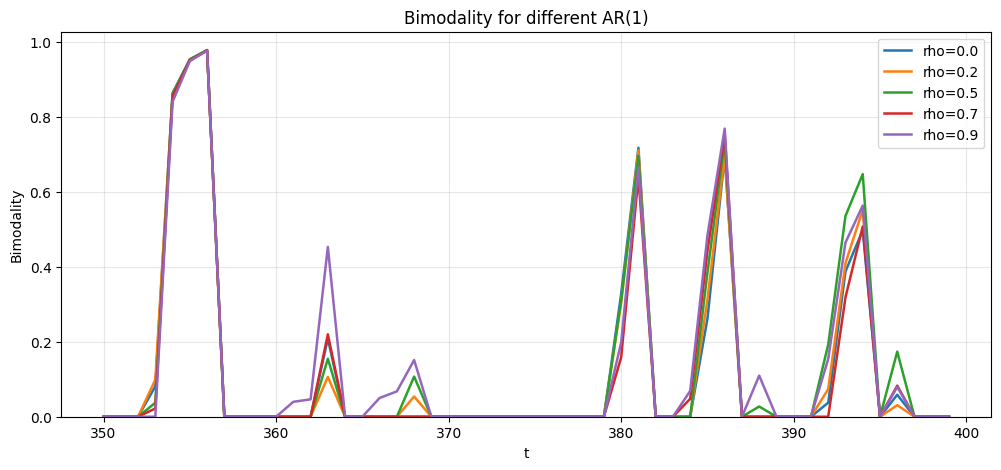

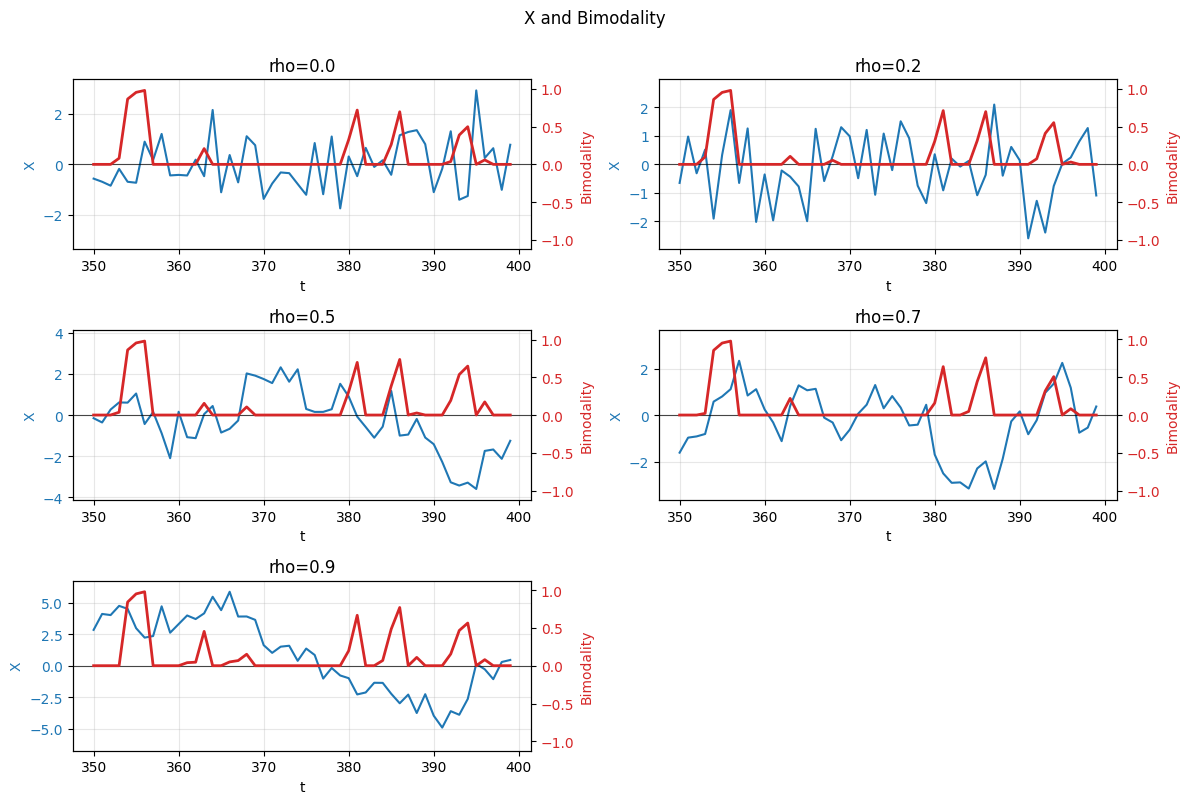

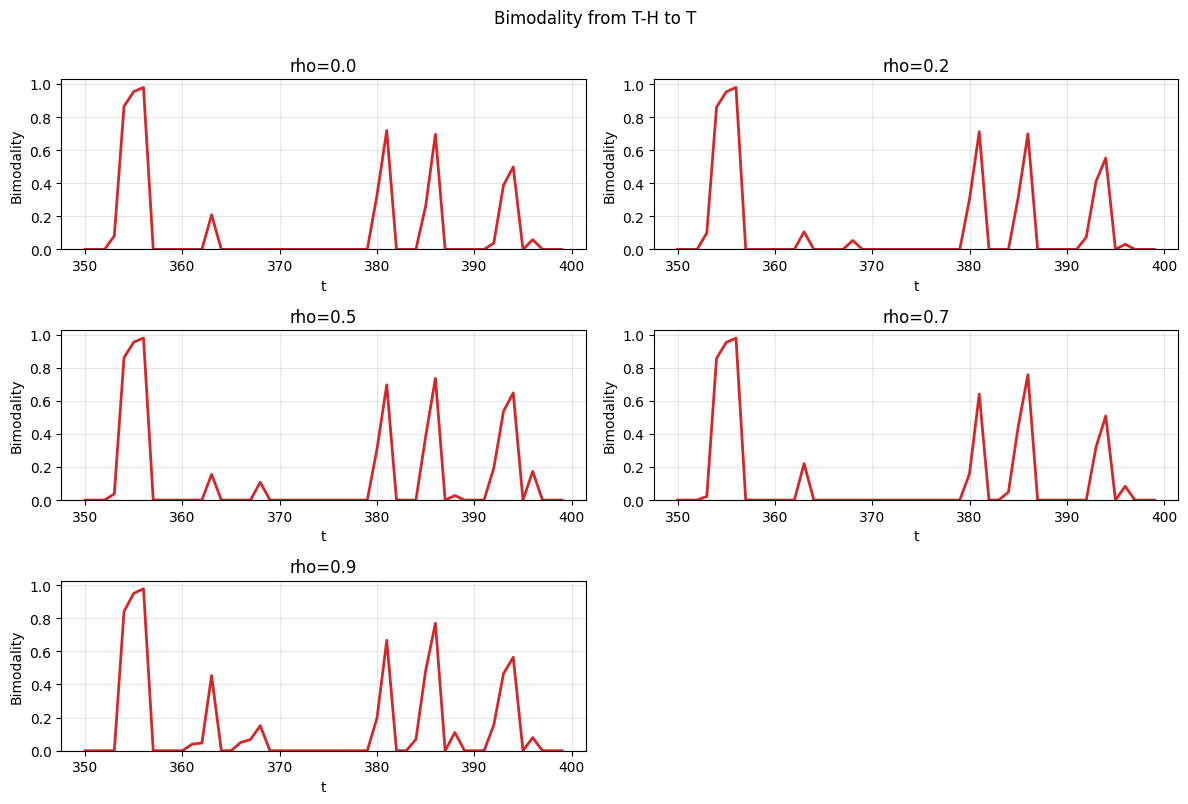

In [10]:
# =========================================================
# Effect of AR(1) 
# =========================================================

# Function to generate AR(1) with Normal(0,1) innovations
def generate_ar1_X(N, rho):
    X = np.zeros(N)
    eta = np.random.normal(0, 1, N)

    for t in range(1, N):
        X[t] = rho * X[t-1] + eta[t]

    return X

rhos = [0.0, 0.2, 0.5, 0.7, 0.9]

exp3_results = {}
N = T + burn + extra

np.random.seed(42)
common_eps = sigma * np.random.standard_cauchy(size=N)

np.random.seed(300)
for rho_val in rhos:
    X_full = generate_ar1_X(N, rho=rho_val)

    y, X = simulate_marx(
        T=T,
        phi=phi,
        psi=psi,
        beta=beta,
        X=X_full,
        eps=common_eps,
        burn=burn,
        extra=extra
    )

    b = bimodality_series(y, X, phi, psi, beta, sigma, grid)

    exp3_results[f"rho={rho_val}"] = {
        "X": X,
        "y": y,
        "b": b
    }


# Plot bimodality for different AR(1)
plt.figure(figsize=(12, 5))
for label, res in exp3_results.items():
    plt.plot(times_lastH, res["b"][-H:], lw=1.8, label=label)

plt.title("Bimodality for different AR(1)")
plt.xlabel("t")
plt.ylabel("Bimodality")
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# Plot X and bimodality on the same plot from T-H onwards
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=False)
axes = axes.ravel()

times_lastH = np.arange(T - H, T)

for ax, (name, res) in zip(axes, exp3_results.items()):
    X_lastH = res["X"][-H:]
    b_lastH = res["b"][-H:]

    # left axis: X
    ax.plot(times_lastH, X_lastH, lw=1.5, color="tab:blue", label="X")
    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("X", color="tab:blue")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.grid(True, alpha=0.3)

    # right axis: bimodality
    ax2 = ax.twinx()
    ax2.plot(times_lastH, b_lastH, lw=2.0, color="tab:red", label="Bimodality")
    ax2.set_ylabel("Bimodality", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    # force both axes to be symmetric around zero
    x_lim = np.max(np.abs(X_lastH))
    b_lim = np.max(np.abs(b_lastH))

    if x_lim == 0:
        x_lim = 1.0
    if b_lim == 0:
        b_lim = 1.0

    # add padding
    pad = 1.15

    ax.set_ylim(-pad * x_lim, pad * x_lim)
    ax2.set_ylim(-pad * b_lim, pad * b_lim)

    # zero line
    ax.axhline(0, color="black", lw=0.8, alpha=0.7)

# remove unused subplot
for j in range(len(exp3_results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("X and Bimodality", y=1)
plt.tight_layout()
plt.show()


# Plot bimodality only from T-H to T
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=False, sharey=False)
axes = axes.ravel()

times_lastH = np.arange(T - H, T)

for ax, (name, res) in zip(axes, exp3_results.items()):
    b_lastH = res["b"][-H:]

    ax.plot(times_lastH, b_lastH, lw=2, color="tab:red")
    ax.axhline(0, color="black", lw=0.8, alpha=0.6)

    ax.set_title(name)
    ax.set_xlabel("t")
    ax.set_ylabel("Bimodality")
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

for j in range(len(exp3_results), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Bimodality from T-H to T", y=1)
plt.tight_layout()
plt.show()
